In [1]:
import numpy as np
from toolbox import (
    Masking,
    combined_frequency_roc_analysis,
    compute_ROC,
    find_all_indices,
    hot_coding,
)
from toolbox.loading import load_data

In [2]:
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)

In [3]:
(
    py_idx,
    patient_no,
    patient_sample,
    Zdata,
    Avg_Cutpats,
    LesionAssessment,
    labels_healthy_vs_cancer,
    labels_cancer_vs_hbd,
    labels_WHO,
) = load_data(path="data", Cutpats_threshold=60, norm="freq")


	Info:	np.abs(Zdata)

Remaining data samples: 244 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 229 

	Info:	z-score Zdata
before: 434.20845093924504 699.3585400487347
Normalized along the frequency axis.

after: -4.3347838749237164e-17 1.000000000000001

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 229 


**Select classification basis task `class_task`**

- `"healthy_vs_cancer"`
- `"cancer_vs_hbd"`
- `"WHO"`

In [4]:
class_task = "healthy_vs_cancer"
# class_task = "cancer_vs_hbd"
# class_task = "WHO"

In [5]:
if class_task == "healthy_vs_cancer":
    print("Healthy vs. cancer\n")
    select_idx = find_all_indices(
        labels_healthy_vs_cancer, ["Healthy", "Cancer"], split=False
    )
    labels = labels_healthy_vs_cancer[select_idx]

elif class_task == "cancer_vs_hbd":
    print("\nHealthy vs. HDB\n")
    select_idx = find_all_indices(
        labels_cancer_vs_hbd, ["Non-cancer", "Cancer"], split=False
    )
    labels = labels_cancer_vs_hbd[select_idx]
elif class_task == "WHO":
    print("\nWHO\n")
    select_idx = find_all_indices(
        labels_WHO,
        ["Healthy", "Cancer", "Mild dysplasia", "Severe dysplasia", "Benign"],
        split=False,
    )
    labels = labels_WHO[select_idx]
Case = patient_no[select_idx]
X = Zdata[select_idx, ...]
Y = hot_coding(labels)

Healthy vs. cancer

Healthy: 89 entries
Cancer: 92 entries
Available cases: ['Cancer' 'Healthy']
Coding: -> forward
{np.str_('Cancer'): [1, 0], np.str_('Healthy'): [0, 1]}


In [6]:
print(X.shape, Y.shape, labels.shape)

(181, 31, 7728) (181, 2) (181,)


NaN are replaced by 0.
(144, 239568) (37, 239568) (144, 2) (37, 2)
Note: Using random sample splitting (not patient-based)


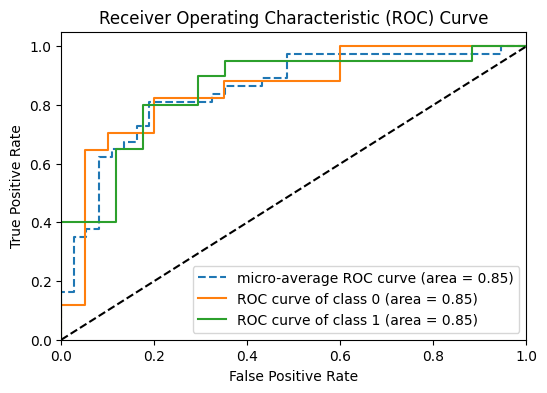

avg_roc_auc=np.float64(0.8529411764705882)


(np.float64(0.8529411764705882),
 {'roc_auc_0': np.float64(0.8529411764705883),
  'roc_auc_1': np.float64(0.8529411764705881)})

In [7]:
compute_ROC(X[:, :, :], Y, test_size=0.2, plot=True)

## Frequency sweep with ranked frequencies from PCA

**1. All IIVV patterns (baseline)**

In [31]:
random_state = 0

Performing 5-fold cross-validation with PCA-based frequency ranking and ROC analysis...
Train patients: [ 0  1  3  4  6  7 10 11 12 13 15 16 19 20 21 22 23 25 27 28 29 30 31 32
 34 35 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 55 56 57 58 60
 61 62 66 67 68 69 70 72 73 74 75 76 77 78 79 81 84 85 86 87 88 89 90 91
 92 95 96 97]
Test patients: [ 2 33 59 18 14 64 65 83 36 82 80  8 54 94 99 63  9 24]
Fold 1: 77.3% train / 22.7% test
Fold 1: 77.3% train / 22.7% test
  Training: 140 samples from 76 patients
  Testing:  41 samples from 18 patients
Fold 1 frequency ranking (top 10): [ 0 30 12 13  8 23 10 16 20 11]
Train patients: [ 0  1  2  4  6  8  9 10 11 12 13 14 15 16 18 19 21 22 23 24 25 28 31 32
 33 34 35 36 37 38 39 40 41 42 43 44 47 49 50 52 53 54 55 56 57 58 59 60
 61 62 63 64 65 66 67 68 70 72 73 74 75 76 79 80 82 83 84 85 87 89 92 94
 95 96 97 99]
Test patients: [77 48 29 46 27  7 45 51 78 86 81 91 90  3 69 88 30 20]
Fold 2: 81.2% train / 18.8% test
Fold 2: 81.2% train / 18.

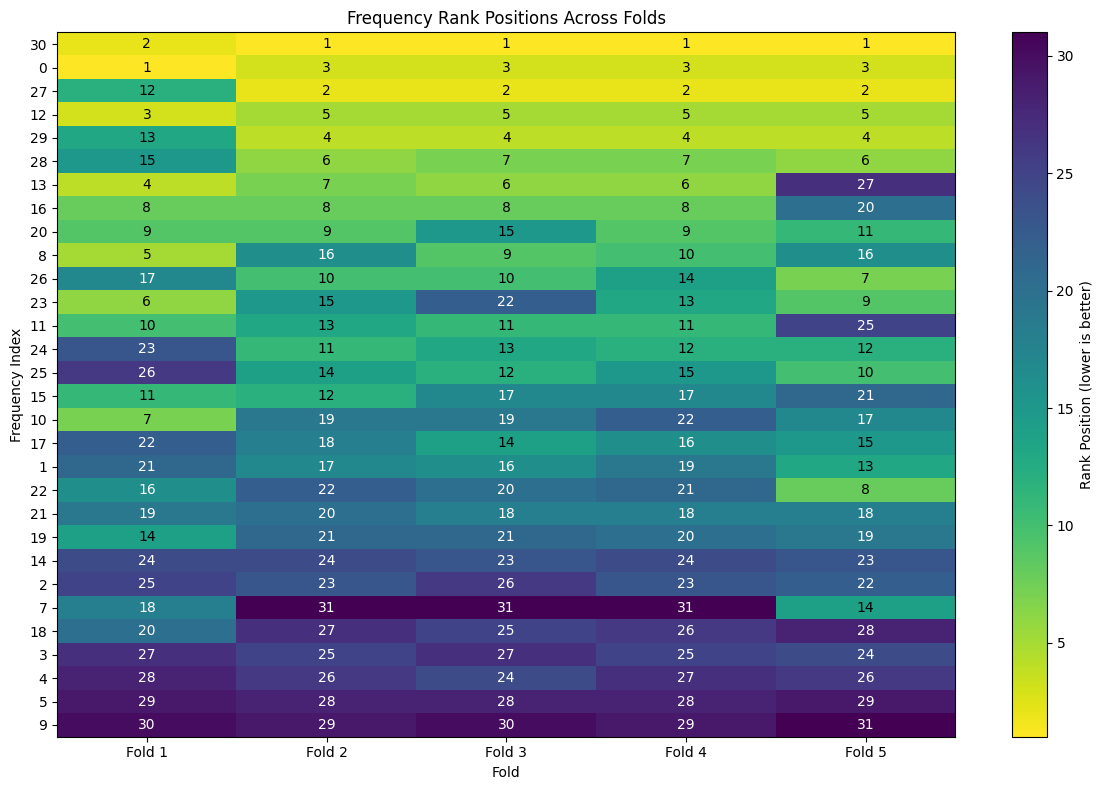

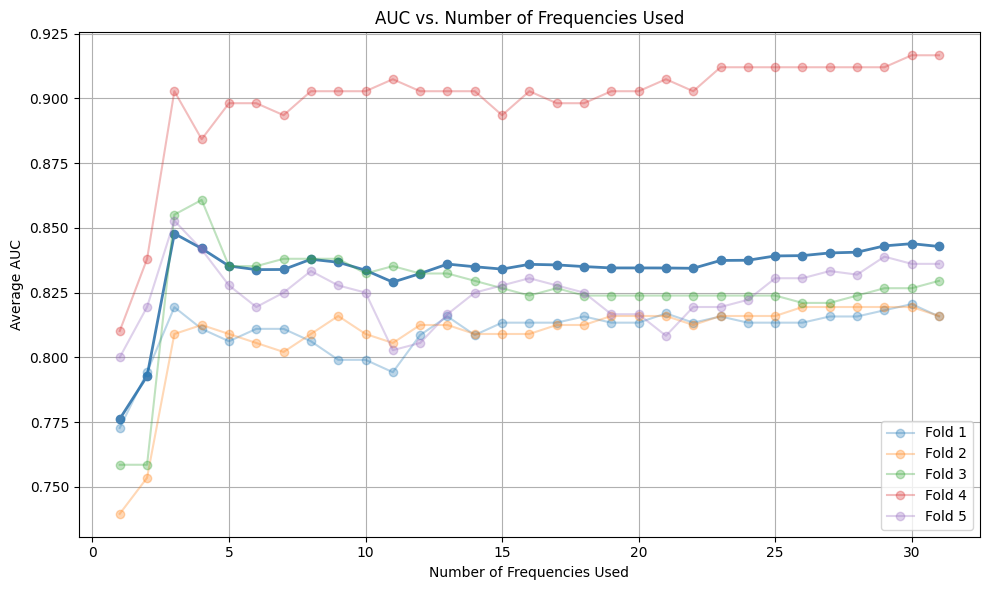

In [32]:
from toolbox.roc_auc import combined_frequency_roc_analysis

aucs_all, top_freqs_all, fold_rankings_all, fold_aucs_all = (
    combined_frequency_roc_analysis(
        X, Y, Case, max_freqs=31, n_folds=5, random_state=random_state
    )
)

___

Testing the different heuristically chosen patterns:

- `mask.IIVV_mask("vv_long_across")`
- `mask.IIVV_mask("vv_long_across_extended")`
- `mask.IIVV_mask("vv_medium_across_extended")`
- `mask.IIVV_mask("vv_distance_close_skip_1")`

**2. Long across `vv_long_across`**

config: vv_long_across=array([[26, 31,  1, 22],
       [26, 31,  1, 21],
       [26, 31,  2, 21],
       [26, 31,  2, 22],
       [27, 30,  4, 24],
       [27, 30,  4, 25],
       [27, 30,  5, 24],
       [27, 30,  5, 25],
       [28, 33,  1,  5],
       [28, 33,  1, 10],
       [28, 33,  5,  6],
       [28, 33,  6, 10],
       [29, 32, 16, 20],
       [29, 32, 16, 25],
       [29, 32, 20, 21],
       [29, 32, 21, 25]])


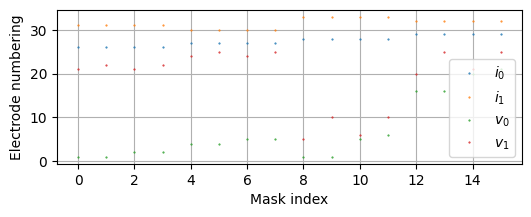

Mask set by IIVV pattern rule.
True: 16 (0.21%)	False: 7712(99.79%)
Performing 5-fold cross-validation with PCA-based frequency ranking and ROC analysis...
Train patients: [ 0  1  3  4  6  7 10 11 12 13 15 16 19 20 21 22 23 25 27 28 29 30 31 32
 34 35 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 55 56 57 58 60
 61 62 66 67 68 69 70 72 73 74 75 76 77 78 79 81 84 85 86 87 88 89 90 91
 92 95 96 97]
Test patients: [ 2 33 59 18 14 64 65 83 36 82 80  8 54 94 99 63  9 24]
Fold 1: 77.3% train / 22.7% test
Fold 1: 77.3% train / 22.7% test
  Training: 140 samples from 76 patients
  Testing:  41 samples from 18 patients
Fold 1 frequency ranking (top 10): [ 0 12 30 13 11  1  8 16 10  7]
Train patients: [ 0  1  2  4  6  8  9 10 11 12 13 14 15 16 18 19 21 22 23 24 25 28 31 32
 33 34 35 36 37 38 39 40 41 42 43 44 47 49 50 52 53 54 55 56 57 58 59 60
 61 62 63 64 65 66 67 68 70 72 73 74 75 76 79 80 82 83 84 85 87 89 92 94
 95 96 97 99]
Test patients: [77 48 29 46 27  7 45 51 78 86 81 91 90  3 69 

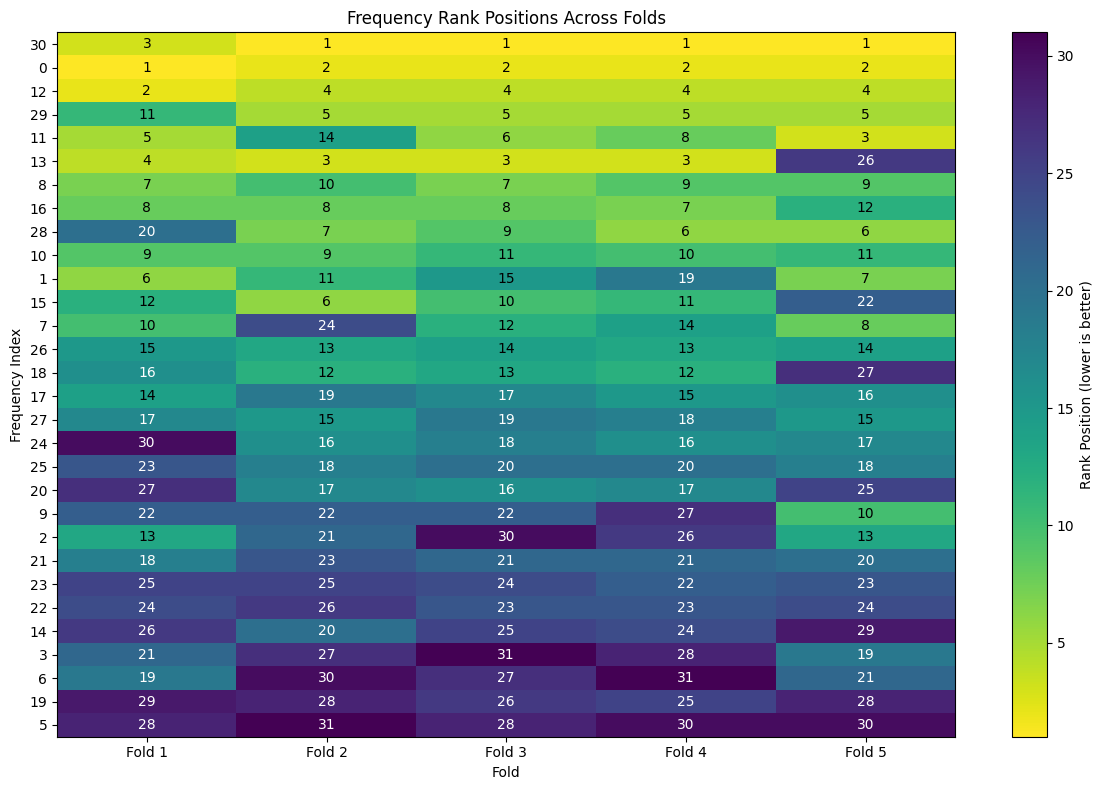

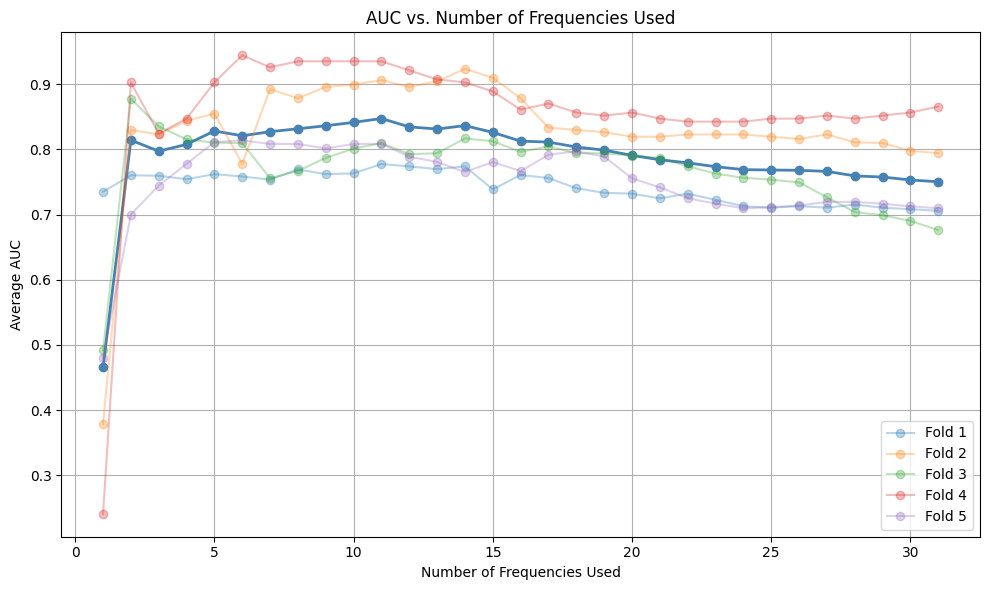

In [33]:
mask.IIVV_mask("vv_long_across")
X_tmp = X[:, :, mask.mask]

aucs_la, top_freqs_la, fold_rankings_la, fold_aucs_la = combined_frequency_roc_analysis(
    X_tmp, Y, Case, max_freqs=31, n_folds=5, random_state=random_state
)

**3. Long across extended `vv_long_across_extended`**

config: vv_long_across_extended={'26_31': [1, 2, 3, 21, 22, 23], '27_30': [3, 4, 5, 23, 24, 25], '28_33': [1, 5, 6, 10, 11, 15], '29_32': [11, 15, 16, 20, 21, 25], '30_26': [1, 2, 3, 23, 24, 25], '31_27': [3, 4, 5, 21, 22, 23], '32_28': [5, 10, 11, 15, 16, 21], '33_29': [1, 6, 11, 15, 20, 25]}


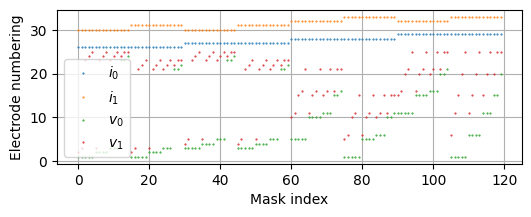

Mask set by IIVV pattern rule.
True: 120 (1.55%)	False: 7608(98.45%)
Performing 5-fold cross-validation with PCA-based frequency ranking and ROC analysis...
Train patients: [ 0  1  3  4  6  7 10 11 12 13 15 16 19 20 21 22 23 25 27 28 29 30 31 32
 34 35 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 55 56 57 58 60
 61 62 66 67 68 69 70 72 73 74 75 76 77 78 79 81 84 85 86 87 88 89 90 91
 92 95 96 97]
Test patients: [ 2 33 59 18 14 64 65 83 36 82 80  8 54 94 99 63  9 24]
Fold 1: 77.3% train / 22.7% test
Fold 1: 77.3% train / 22.7% test
  Training: 140 samples from 76 patients
  Testing:  41 samples from 18 patients
Fold 1 frequency ranking (top 10): [ 0 30 12 13 15  8 11 10 16 17]
Train patients: [ 0  1  2  4  6  8  9 10 11 12 13 14 15 16 18 19 21 22 23 24 25 28 31 32
 33 34 35 36 37 38 39 40 41 42 43 44 47 49 50 52 53 54 55 56 57 58 59 60
 61 62 63 64 65 66 67 68 70 72 73 74 75 76 79 80 82 83 84 85 87 89 92 94
 95 96 97 99]
Test patients: [77 48 29 46 27  7 45 51 78 86 81 91 90  3 69

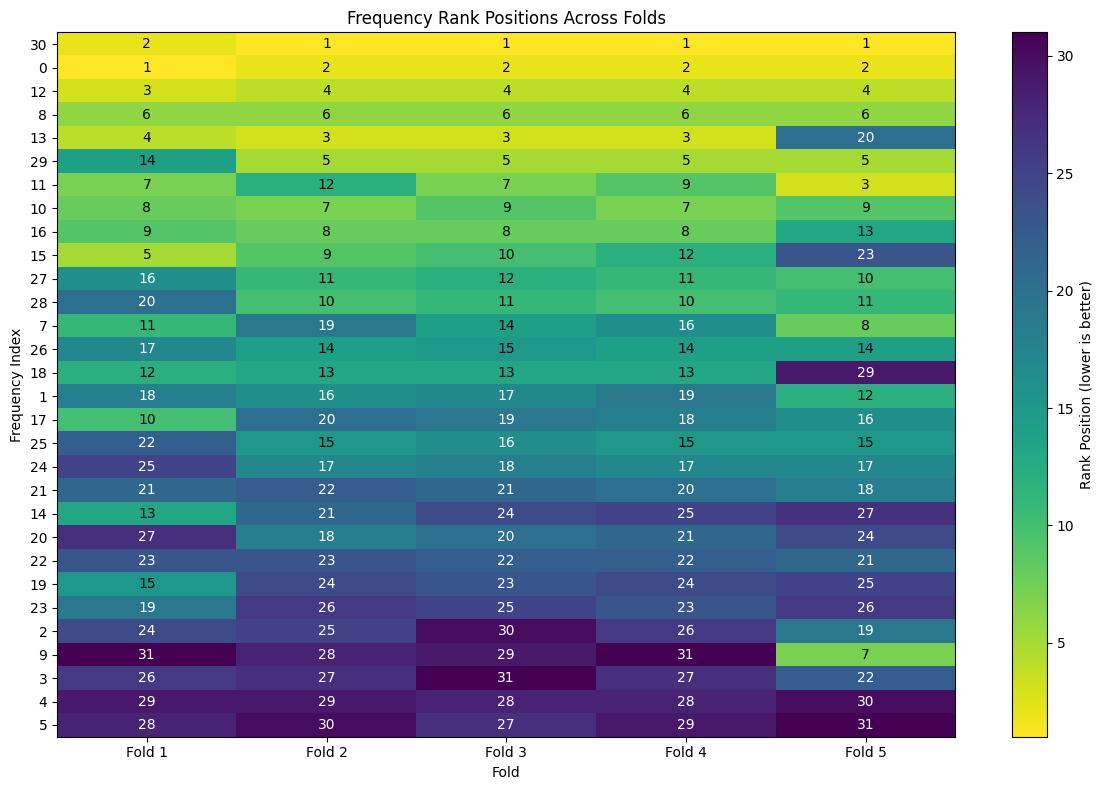

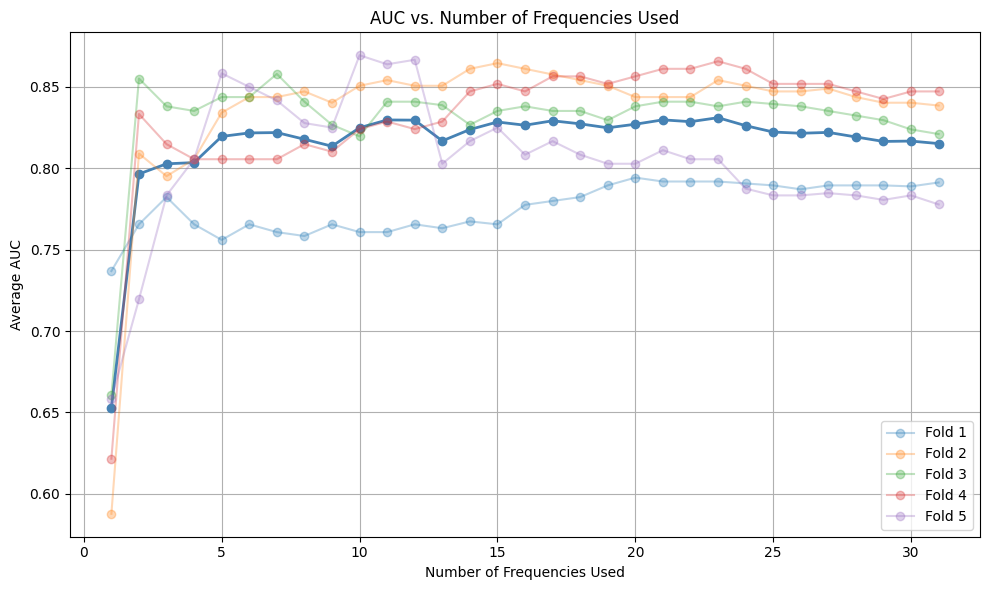

In [34]:
mask.IIVV_mask("vv_long_across_extended")
X_tmp = X[:, :, mask.mask]

aucs_lae, top_freqs_lae, fold_rankings_lae, fold_aucs_lae = (
    combined_frequency_roc_analysis(
        X_tmp, Y, Case, max_freqs=31, n_folds=5, random_state=random_state
    )
)

**4. Medium across extended `vv_medium_across_extended`**

config: vv_medium_across_extended={'26_31': [6, 7, 8, 16, 17, 18], '27_30': [8, 9, 10, 18, 19, 20], '28_33': [2, 4, 7, 9, 12, 14], '29_32': [12, 14, 17, 19, 22, 24], '30_26': [6, 7, 8, 18, 19, 20], '31_27': [8, 9, 10, 16, 17, 18], '32_28': [12, 14, 17, 19, 22, 24], '33_29': [2, 7, 12, 14, 19, 24]}


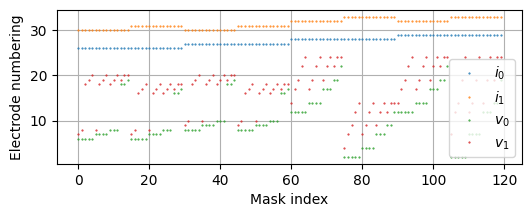

Mask set by IIVV pattern rule.
True: 120 (1.55%)	False: 7608(98.45%)
Performing 5-fold cross-validation with PCA-based frequency ranking and ROC analysis...
Train patients: [ 1  2  3  6  7  8  9 10 12 14 15 16 18 19 21 22 23 25 27 28 30 32 33 34
 35 36 37 39 40 41 44 45 46 48 49 50 51 52 53 54 55 56 57 59 60 61 62 63
 64 66 67 68 69 72 73 74 75 77 78 79 80 81 82 83 84 85 86 88 89 90 91 92
 94 96 97 99]
Test patients: [43 24 58 76  0 29 42 70 11 47 87 38 95 65 13  4 20 31]
Fold 1: 79.6% train / 20.4% test
Fold 1: 79.6% train / 20.4% test
  Training: 144 samples from 76 patients
  Testing:  37 samples from 18 patients
Fold 1 frequency ranking (top 10): [30 27  0 29 12 13 28 16 11 26]
Train patients: [ 0  1  2  3  4  7  8  9 11 13 14 15 19 20 21 22 23 24 25 27 28 29 30 31
 32 35 37 38 39 40 41 42 43 44 46 47 48 49 51 53 54 55 56 57 58 59 60 61
 62 63 64 65 66 67 70 75 76 77 78 79 80 83 84 85 86 87 88 89 90 91 92 94
 95 96 97 99]
Test patients: [52 68 16 72 82 33 36 12 69 73 34 81 10 74  6

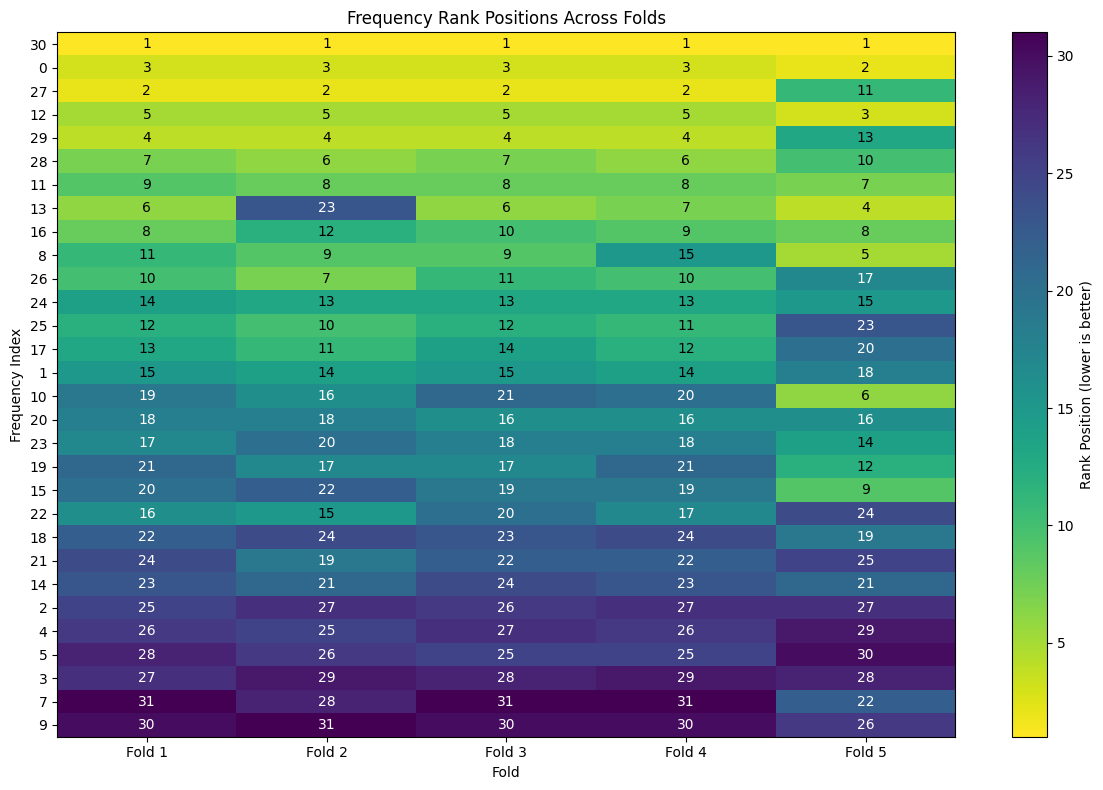

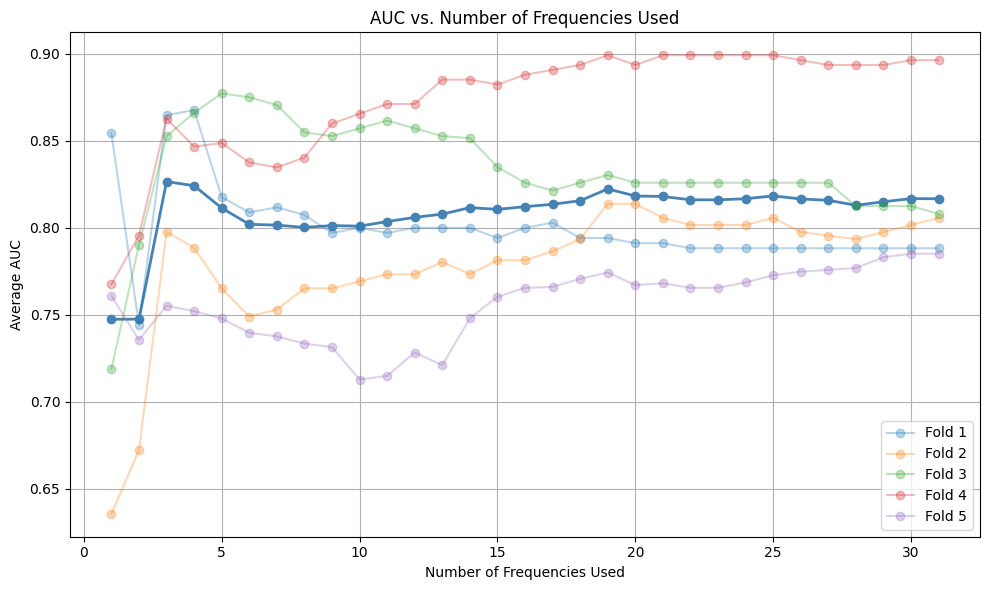

In [35]:
mask.IIVV_mask("vv_medium_across_extended")
X_tmp = X[:, :, mask.mask]

aucs_mae, top_freqs_mae, fold_rankings_mae, fold_aucs_mae = (
    combined_frequency_roc_analysis(
        X_tmp, Y, Case, max_freqs=31, n_folds=5, random_state=42
    )
)

**5. Distance close skip 1 `vv_distance_close_skip_1`**

config: vv_distance_close_skip_1={'26_28': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10], '27_29': [4, 5, 9, 10, 14, 15, 19, 20, 24, 25], '28_30': [4, 5, 9, 10, 14, 15, 19, 20, 24, 25], '29_31': [16, 17, 18, 19, 20, 21, 22, 23, 24, 25], '30_32': [16, 17, 18, 19, 20, 21, 22, 23, 24, 25], '31_33': [1, 2, 6, 7, 11, 12, 16, 17, 21, 22], '32_26': [1, 2, 6, 7, 11, 12, 16, 17, 21, 22], '33_27': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]}


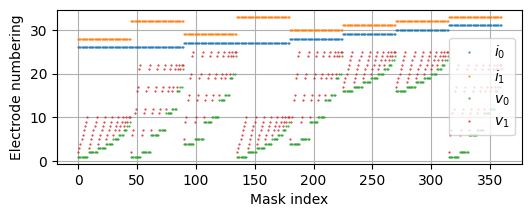

Mask set by IIVV pattern rule.
True: 360 (4.66%)	False: 7368(95.34%)
Performing 5-fold cross-validation with PCA-based frequency ranking and ROC analysis...
Train patients: [ 1  2  3  6  7  8  9 10 12 14 15 16 18 19 21 22 23 25 27 28 30 32 33 34
 35 36 37 39 40 41 44 45 46 48 49 50 51 52 53 54 55 56 57 59 60 61 62 63
 64 66 67 68 69 72 73 74 75 77 78 79 80 81 82 83 84 85 86 88 89 90 91 92
 94 96 97 99]
Test patients: [43 24 58 76  0 29 42 70 11 47 87 38 95 65 13  4 20 31]
Fold 1: 79.6% train / 20.4% test
Fold 1: 79.6% train / 20.4% test
  Training: 144 samples from 76 patients
  Testing:  37 samples from 18 patients
Fold 1 frequency ranking (top 10): [30  0 27 29 12 13 28 16 15 25]
Train patients: [ 0  1  2  3  4  7  8  9 11 13 14 15 19 20 21 22 23 24 25 27 28 29 30 31
 32 35 37 38 39 40 41 42 43 44 46 47 48 49 51 53 54 55 56 57 58 59 60 61
 62 63 64 65 66 67 70 75 76 77 78 79 80 83 84 85 86 87 88 89 90 91 92 94
 95 96 97 99]
Test patients: [52 68 16 72 82 33 36 12 69 73 34 81 10 74  6

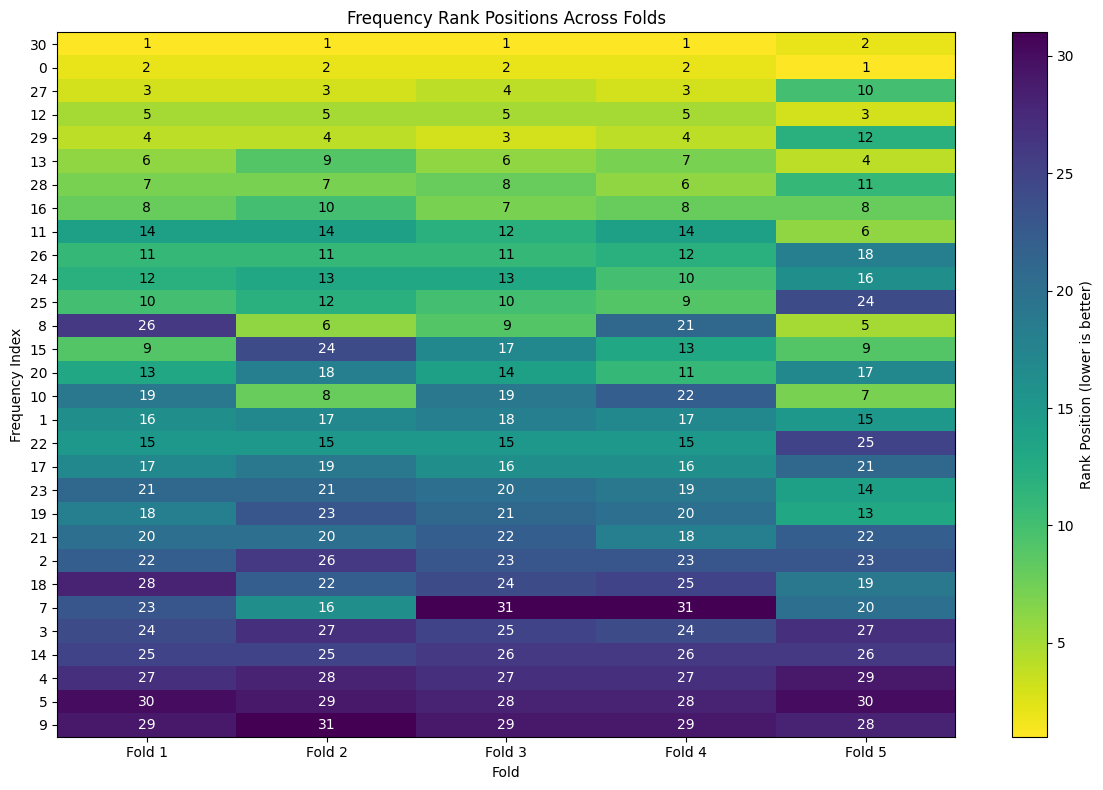

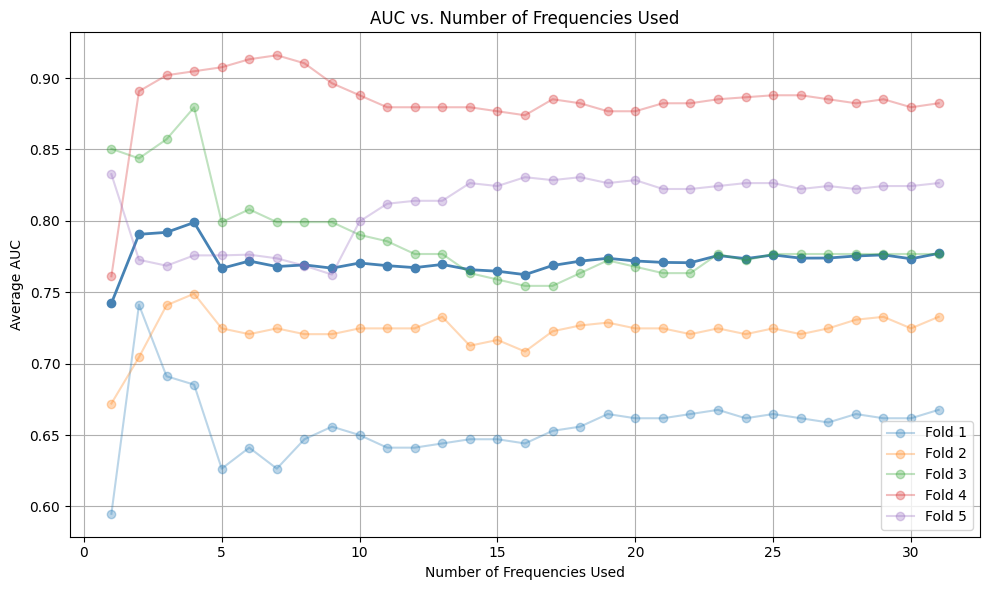

In [36]:
mask.IIVV_mask("vv_distance_close_skip_1")
X_tmp = X[:, :, mask.mask]

aucs_s1, top_freqs_s1, fold_rankings_s1, fold_aucs_s1 = combined_frequency_roc_analysis(
    X_tmp, Y, Case, max_freqs=31, n_folds=5, random_state=42
)

## Save/overview of results

In [37]:
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

color_palette_full = {
    "Healthy": "#003F5C",
    "Benign": "#58508D",
    "Dysplasia": "#7A5195",
    "Mild dysplasia": "#BC5090",
    "Non-cancer": "#DD5182",
    "Severe dysplasia": "#FF6361",
    "Cancer": "#FFA600",
}

custom_colors = list(color_palette_full.values())

custom_cmap = mcolors.ListedColormap(custom_colors, name="custom_disease_cmap")

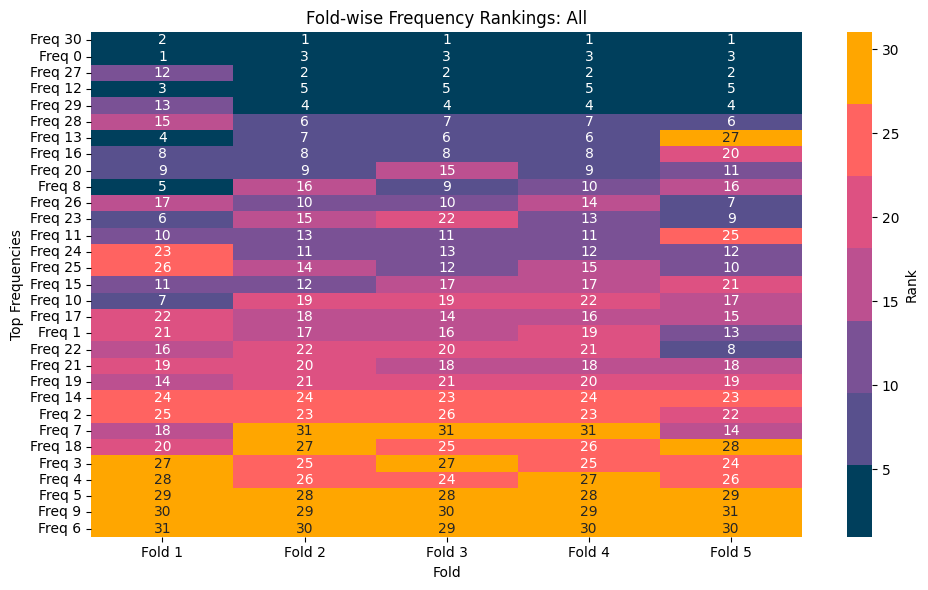

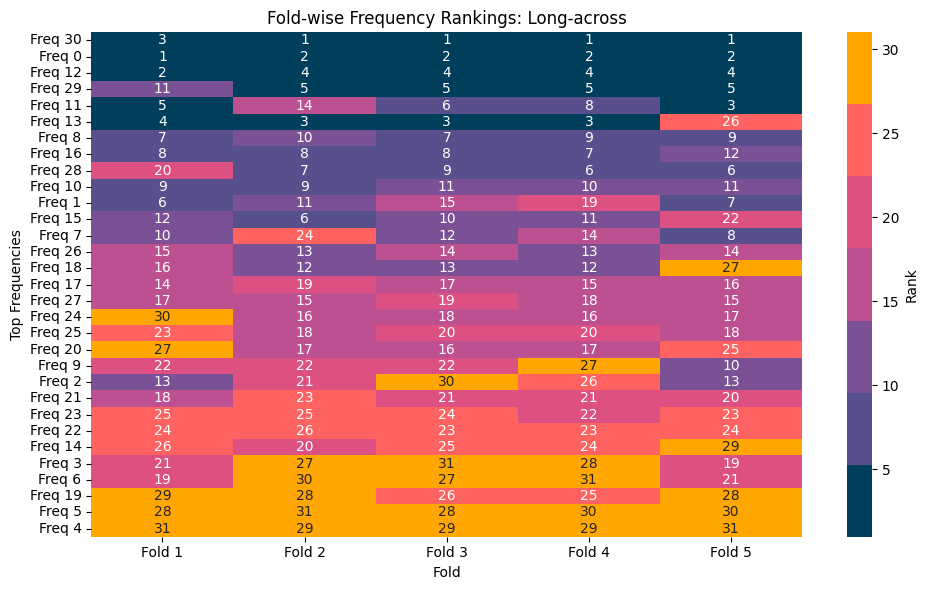

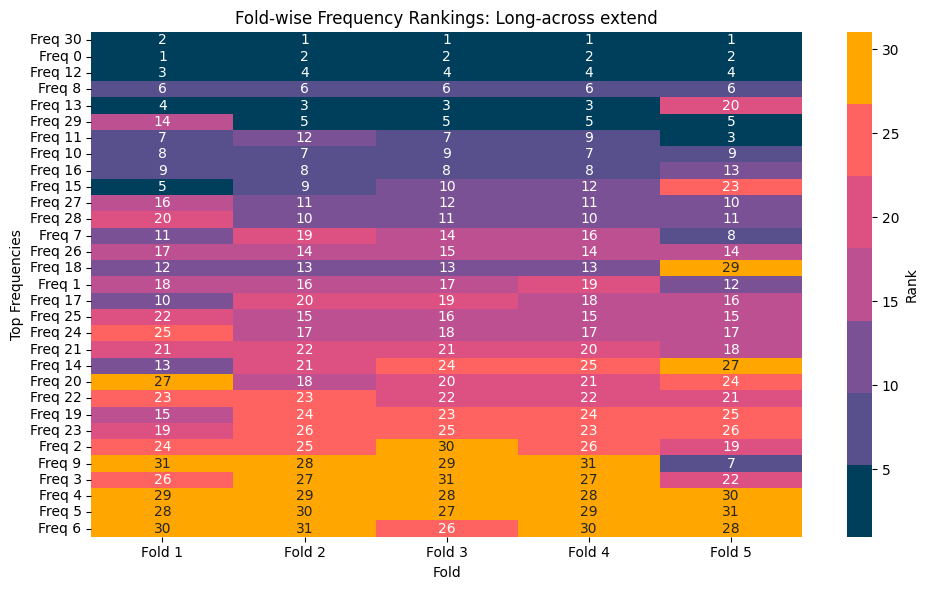

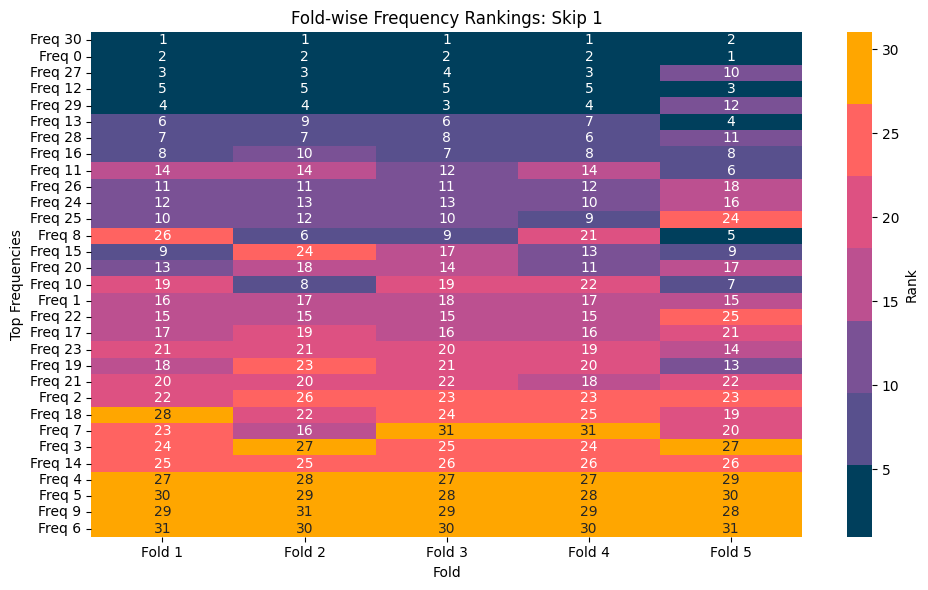

In [41]:
def plot_fold_rankings(fold_rankings_dict, top_n_freqs=20):
    """
    Visualizes fold frequency rankings as heatmaps for multiple ranking sets.

    Parameters:
        fold_rankings_dict : dict
            Dictionary where keys are method names and values are lists of np.arrays (fold rankings).
        top_n_freqs : int
            Number of top composite frequencies to display in the heatmap.
    """
    for name, rankings in fold_rankings_dict.items():
        n_folds = len(rankings)
        n_freqs = len(rankings[0])

        # Composite ranking across folds for sorting
        score_accumulator = np.zeros(n_freqs)
        for fold in rankings:
            for rank, freq_idx in enumerate(fold):
                score_accumulator[freq_idx] += n_freqs - rank

        composite_ranking = np.argsort(score_accumulator)[::-1][:top_n_freqs]

        # Create rank matrix: rows = top freqs, cols = folds
        rank_matrix = np.full((top_n_freqs, n_folds), np.nan)
        for f_idx, fold in enumerate(rankings):
            for i, freq in enumerate(composite_ranking):
                pos = np.where(fold == freq)[0]
                if pos.size > 0:
                    rank_matrix[i, f_idx] = pos[0] + 1  # +1 for 1-based rank

        # Plot heatmap
        plt.figure(figsize=(10, 6))
        sns.heatmap(
            rank_matrix,
            annot=True,
            fmt=".0f",
            cmap=custom_cmap,
            cbar_kws={"label": "Rank"},
            xticklabels=[f"Fold {i+1}" for i in range(n_folds)],
            yticklabels=[f"Freq {f}" for f in composite_ranking],
        )
        plt.title(f"Fold-wise Frequency Rankings: {name}")
        plt.xlabel("Fold")
        plt.ylabel("Top Frequencies")
        plt.tight_layout()
        plt.show()


fold_rankings_dict = {
    "All": fold_rankings_all,
    "Long-across": fold_rankings_la,
    "Long-across extend": fold_rankings_lae,
    "Skip 1": fold_rankings_s1,
}

plot_fold_rankings(fold_rankings_dict, top_n_freqs=31)

___